In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from LinearModels import LinearRegression

### Data

In [5]:
rng = np.random.default_rng(seed=40)
X = rng.uniform(0, 1, size=(10, 1))
Y = 5*X +rng.standard_normal(size=(10, 1))
print(X, Y, sep='\n')

[[0.7298985 ]
 [0.69341496]
 [0.94192102]
 [0.05965206]
 [0.69052097]
 [0.92239752]
 [0.47568318]
 [0.33839069]
 [0.60188281]
 [0.73062776]]
[[ 3.84280139]
 [ 3.61172694]
 [ 5.09569885]
 [-0.27232824]
 [ 2.51702122]
 [ 3.27647014]
 [ 2.7079357 ]
 [ 1.48441222]
 [ 3.4361852 ]
 [ 3.69814846]]


In [6]:
def plot_data(X, Y):
    fig, ax = plt.subplots()
    ax.scatter(X, Y)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    plt.show()

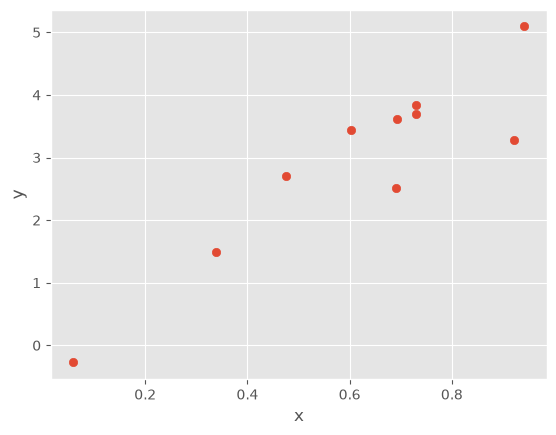

In [7]:
plot_data(X, Y)

### Comparision of linear models for different choice of loss functions:

In [8]:
def model_estimation(X, Y, w, b):
    models = {('mse', None):None,
              ('mae', None):None,
              ('mse','l1'):None,
              ('mae','l2'):None}
    # Intiate the model for each type in the above.

    for model_type in models:
        models[model_type] = LinearRegression(w, b,
                                               loss_func=model_type[0],
                                               reg=model_type[1], lambda_= 0.5)
    # Let the models learn.

    for model_type, model in models.items():
        if model_type[1] == None:
            print(f'Model Loss function: {model_type[0]} with no Regularzition')
        else:
            print(f"Model Loss Function: {model_type[0]} with {model_type[1]}")
        model.learn(X, Y, alpha=0.001, epochs=20_000)

    # now each learned at least a bit from the data, now let's plot the hyperplane
    # estimation for each model.

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(X, Y, label='Data Points')

    x_val = np.linspace(0,1)

    for model_type, model in models.items():
        if model_type[1] == None:
            name = model_type[0] + ' with no Reg.'
        else:
            name = model_type[0] +" with " +  model_type[1] + ' Reg.'
        w = model.w[0,0]
        b = model.b

        y_val = w*x_val + b

        ax.plot(x_val, y_val, label=name.upper())

    ax.set_title('Comparison of Linear Regression Models: Loss Functions and Regularization')
    ax.set_xlabel('Feature (x)')
    ax.set_ylabel('Target (y)')
    ax.set_xlim([0, 1])

    ax.legend()

    fig.savefig('comparision_linear_models.jpg', dpi=1200)
        

    




In [9]:
w = np.ones((1, 1))
b = 0.5

Model Loss function: mse with no Regularzition
Epoch: 10000, Loss: 0.2924768132216222
Epoch: 20000, Loss: 0.21567454570388397
Model Loss function: mae with no Regularzition
Epoch: 10000, Loss: 0.6480537545883812
Epoch: 20000, Loss: 0.5524274343839534
Model Loss Function: mse with l1
Epoch: 10000, Loss: 0.4691852590041553
Epoch: 20000, Loss: 0.4253394587187035
Model Loss Function: mae with l2
Epoch: 10000, Loss: 0.8534112348384381
Epoch: 20000, Loss: 0.8515257648530192


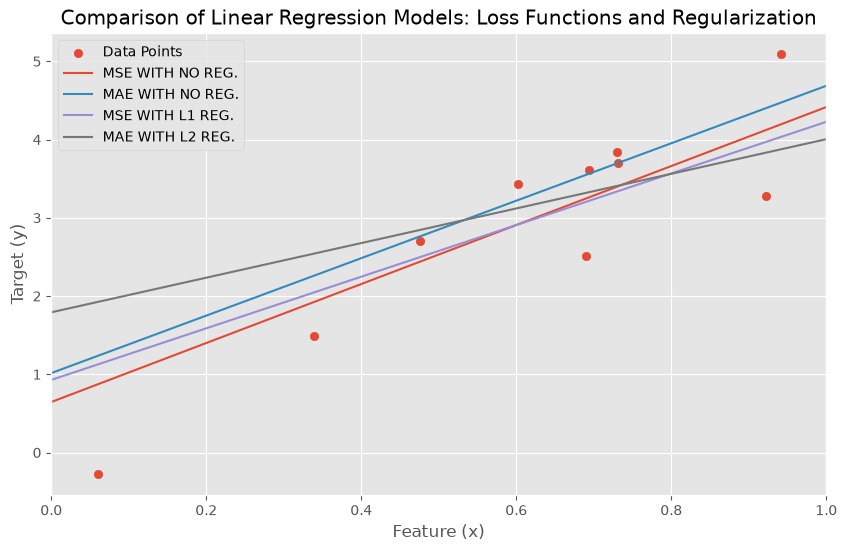

In [10]:
model_estimation(X, Y, w, b)

In [ ]:
str.upper